In [2]:
import urllib.request
import zipfile
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.neural_network import MLPClassifier

os.makedirs('data', exist_ok=True)

url = 'https://archive.ics.uci.edu/static/public/563/iranian+churn+dataset.zip'
zip_path = 'data/iranian_churn.zip'

try:
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('data')
    data = pd.read_csv('data/Customer Churn.csv')
    print("Dataset downloaded and loaded successfully! Shape:", data.shape)
except Exception as e:
    print("Failed to download from UCI, attempting alternative load:", e)


Dataset downloaded and loaded successfully! Shape: (3150, 14)


### მონაცემთა წყარო

პროექტში გამოყენებულია ღია მონაცემთა ნაკრები
**Iranian Churn Dataset (2020)**, რომელიც გამოქვეყნებულია
UCI Machine Learning Repository-ზე.

მონაცემები შეგროვებულია ირანის სატელეკომუნიკაციო
კომპანიაში 12 თვის განმავლობაში და მოიცავს 3150
მომხმარებლის მონაცემებს.

- **წყარო:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset)
- **ლიცენზია:** Creative Commons Attribution 4.0 (CC BY 4.0)
- **DOI:** https://doi.org/10.24432/C5JW3Z


## ნაწილი 1. პრობლემის განსაზღვრა და მონაცემების ანალიზი

**ბიზნესპრობლემა:** სატელეკომუნიკაციო კომპანია კარგავს მომხმარებლებს და სურს მათი შენარჩუნების გაუმჯობესება.

**AI სისტემის მიზანი:** მომხმარებლის ქცევითი მონაცემების საფუძველზე განსაზღვროს, რამდენად მაღალია სერვისის დატოვების რისკი.

**ბიზნესღირებულება:** კომპანიამ დროულად გამოავლინოს მაღალი რისკის მომხმარებლები და მიიღოს შესაბამისი ზომები, მაგალითად, შესთავაზოს ფასდაკლება ან პერსონალიზებული შეტყობინება.

**წესებზე დაფუძნებული სისტემა და მანქანური სწავლება:**

წესებზე დაფუძნებულ სისტემას, იმის გათვალისწინებით, რომ ადამიანის მიერ წინასწარ გაწერილ წესებზეა აგებული, შეზღუდული შესაძლებლობები აქვს. მაგალითად, შეგვიძლია განვსაზღვროთ წესი, რომლის მიხედვითაც საჩივრის მქონე მომხმარებელი მაღალი რისკის ჯგუფში მოხვდება. თუმცა ამ შემთხვევაში მომხმარებლის სხვა მახასიათებლები შეიძლება არ იყოს გათვალისწინებული.

მანქანური სწავლება კი მონაცემებზე დაყრდნობით სწავლობს კანონზომიერებებს და არ არის შემოსაზღვრული ადამიანის მიერ წინასწარ განსაზღვრული შემთხვევებით. მას შეუძლია რამდენიმე მახასიათებლის ერთდროულად გათვალისწინება და ისეთი კავშირების აღმოჩენა, რომლებიც ადამიანს შეიძლება გამორჩეს. შესაბამისად, ხარისხიანი მონაცემებისა და სწორად გაწვრთნილი მოდელის შემთხვევაში შესაძლებელია მომხმარებლის წასვლის რისკის უფრო ზუსტად განსაზღვრა.


- **head()** — აჩვენებს პირველ 5 ჩანაწერს, რათა გავეცნოთ მონაცემების სტრუქტურას.
- **shape** — აჩვენებს მონაცემების რაოდენობას (3150 ჩანაწერი, 14 სვეტი).
- **info()** — ამოწმებს მონაცემთა ტიპებს და გამოტოვებულ მნიშვნელობებს. ყველა სვეტი რიცხვითია და გამოტოვებული მნიშვნელობები არ გვხვდება.
- **describe()** — ითვლის ძირითად სტატისტიკურ მაჩვენებლებს: საშუალოს, მედიანას, მინიმუმს, მაქსიმუმს და სხვ.
- **value_counts()** — ითვლის თითოეული მნიშვნელობის სიხშირეს. `Charge Amount`-ში აღმოვაჩინეთ 7 ჩანაწერი მნიშვნელობით 10, თუმცა დოკუმენტაციაში მითითებულია დიაპაზონი 0–9.

In [2]:
data.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [3]:
data.shape

(3150, 14)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [5]:
data.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [6]:
data["Charge  Amount"].value_counts()

,count
Charge Amount,
0,1768
1,617
2,395
3,199
4,76
5,30
8,19
9,14
7,14


In [7]:
data['Churn'].value_counts()

,count
Churn,
0,2655
1,495



#### ვიზუალიზაციები და დასკვნები

**1. Churn Distribution**

წრიული დიაგრამა გვიჩვენებს, მომხმარებლების რა ნაწილმა დატოვა სერვისი. მომხმარებლების 84.3% დარჩა, ხოლო 15.7%-მა დატოვა სერვისი. მონაცემები არ არის დაბალანსებული, რაც მოდელის შეფასებისას უნდა გავითვალისწინოთ.

**2. Complaints vs Churn**

მომხმარებლები დავაჯგუფეთ საჩივრის არსებობის მიხედვით და თითოეულ ჯგუფში გამოვთვალეთ Churn-ის პროცენტული მაჩვენებელი. იმ მომხმარებლების 83%-მა, რომლებმაც საჩივარი დააფიქსირეს, დატოვა სერვისი, ხოლო მეორე ჯგუფში ეს მაჩვენებელი მხოლოდ 10.1%-ია. შესაბამისად, საჩივარი შეიძლება იყოს მომხმარებლის წასვლის მნიშვნელოვანი ინდიკატორი.

**3. Subscription Length vs Churn**

გამოვთვალეთ მომხმარებლების წასვლის პროცენტული მაჩვენებელი გამოწერის ხანგრძლივობის მიხედვით. გრაფიკიდან ჩანს, რომ ეს მაჩვენებელი შედარებით მაღალია ახალ მომხმარებლებში, თუმცა გამოწერის ხანგრძლივობის ზრდასთან ერთად ყოველთვის არ მცირდება.

**4. Churn Rate by Age Group**

crosstab-ის გამოყენებით გამოვთვალეთ თითოეულ ასაკობრივ ჯგუფში წასული მომხმარებლების პროცენტული წილი. ყველაზე მაღალი მაჩვენებელი 45 წლის კატეგორიაშია (20%), ხოლო ყველაზე დაბალი — 15 და 55 წლის კატეგორიებში. შესაბამისად, ასაკსა და მომხმარებლის წასვლას შორის გარკვეული კავშირი შეინიშნება.

**Frequency of Use vs Churn**

ამ გრაფიკზე გამოვთვალეთ მომხმარებლების წასვლის პროცენტული მაჩვენებელი გამოყენების სიხშირის მიხედვით. მიზანი იყო გაგვეგო, ხომ არ არის კავშირი სერვისის გამოყენების ინტენსივობასა და churn risk-ს შორის.

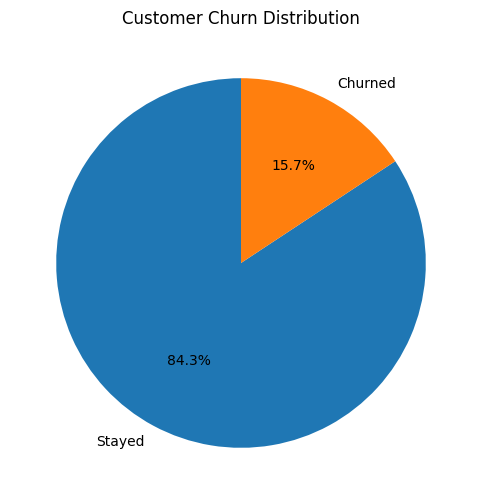

In [8]:
churn_counts = data["Churn"].value_counts().sort_index()

plt.figure(figsize=(6, 6))

plt.pie(churn_counts, labels=["Stayed", "Churned"], autopct="%1.1f%%", startangle=90)

plt.title("Customer Churn Distribution")
plt.show()

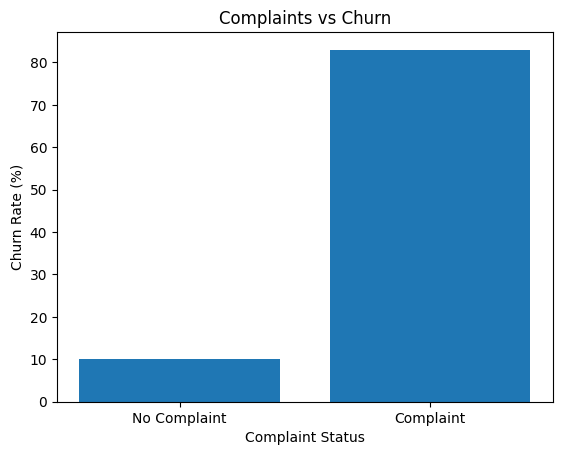

In [9]:
complaint_churn = data.groupby("Complains")["Churn"].mean() * 100

plt.bar(["No Complaint", "Complaint"], complaint_churn)
plt.title("Complaints vs Churn")
plt.xlabel("Complaint Status")
plt.ylabel("Churn Rate (%)")
plt.show()

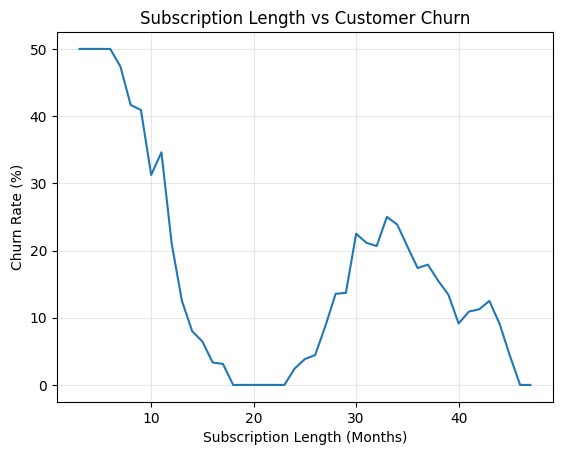

In [10]:
sth = data.groupby('Subscription  Length')['Churn'].mean() * 100
plt.plot(sth.index, sth.values)
plt.title("Subscription Length vs Customer Churn")
plt.xlabel("Subscription Length (Months)")
plt.ylabel("Churn Rate (%)")
plt.grid(alpha=0.3)
plt.show()

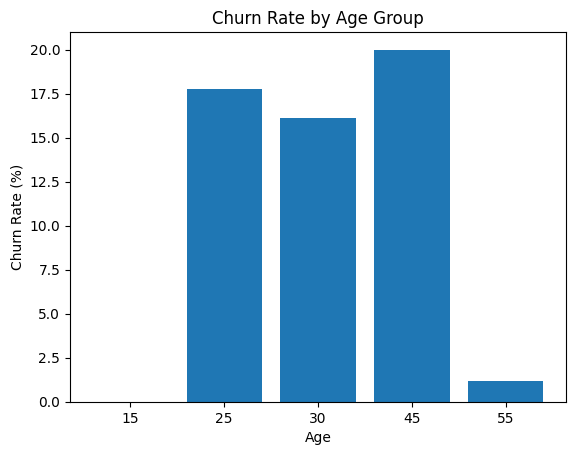

In [11]:
age_churn = pd.crosstab(data['Age'], data['Churn'], normalize='index') * 100
plt.bar(age_churn.index.astype(str), age_churn[1])
plt.title("Churn Rate by Age Group")
plt.xlabel("Age")
plt.ylabel("Churn Rate (%)")
plt.show()


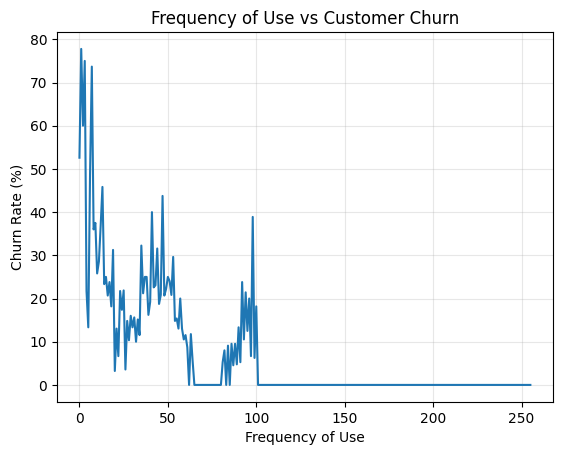

In [12]:
freq_churn = data.groupby("Frequency of use")["Churn"].mean() * 100

plt.plot(freq_churn.index, freq_churn.values)
plt.title("Frequency of Use vs Customer Churn")
plt.xlabel("Frequency of Use")
plt.ylabel("Churn Rate (%)")
plt.grid(alpha=0.3)
plt.show()

## ნაწილი 2. Supervised Learning - პროგნოზირება


#### Features და Target-ის განსაზღვრა

**Target (y):**
- Churn — მომხმარებელი დატოვებს თუ არა სერვისს (0 — დარჩა, 1 — დატოვა).

**Features (X):**
- Call  Failure — წარუმატებელი ზარების რაოდენობა.
- Complains — საჩივრის არსებობა.
- Subscription  Length — გამოწერის ხანგრძლივობა.
- Charge  Amount — გადასახადის დონე.
- Seconds of Use — საუბრის ხანგრძლივობა.
- Frequency of use — გამოყენების სიხშირე.
- Frequency of SMS — გაგზავნილი SMS-ების რაოდენობა.
- Distinct Called Numbers — განსხვავებული ნომრების რაოდენობა.
- Tariff Plan — სატარიფო გეგმა.
- Status — მომხმარებლის აქტიურობის სტატუსი.
- Age — მომხმარებლის ასაკი.



- მონაცემები გასუფთავებულია არასაჭირო მახასიათებლებისგან და გამოვყეთ target

In [13]:
X = data.drop(columns=["Age Group", "Customer Value", "Churn"])

In [14]:
Y = data["Churn"]

- train_test_split() — მონაცემები დაყოფილია სასწავლო (80%) და სატესტო (20%) ნაწილებად.

- სასწავლო მონაცემები გამოიყენება მოდელის გასაწვრთნელად, ხოლო სატესტო — საბოლოო შეფასებისთვის.

In [15]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

- გამოყენებულია Decision Tree Classifier.

- DecisionTreeClassifier() — ქმნის კლასიფიკაციის მოდელს.

- max_depth — განსაზღვრავს ხის მაქსიმალურ სიღრმეს და გვეხმარება Overfitting-ის კონტროლში.

- random_state=42 — გამოიყენება შედეგების განმეორებადობისთვის.

- fit() — მოდელს წვრთნის სასწავლო მონაცემებზე.

- predict() — გაწვრთნილი მოდელი აკეთებს პროგნოზებს.

In [16]:
for depth in [2, 4, 6, 8]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)

    scores = cross_val_score(model, x_train, y_train, cv=5, scoring="accuracy") * 100

    print(f"Depth: {depth}, Mean Accuracy: {scores.mean():.2f}")

Depth: 2, Mean Accuracy: 90.00
Depth: 4, Mean Accuracy: 91.47
Depth: 6, Mean Accuracy: 92.02
Depth: 8, Mean Accuracy: 92.86


In [17]:
sl_model = DecisionTreeClassifier(max_depth=8, random_state=42)
sl_model.fit(x_train, y_train)
sl_y_predict = sl_model.predict(x_test)

accuracy = accuracy_score(y_test, sl_y_predict) * 100
baseline_accuracy = (y_test == 0).mean() * 100

print(f"Accuracy: {accuracy:.2f}")
print(f"Baseline Accuracy: {baseline_accuracy:.2f}")

Accuracy: 93.02
Baseline Accuracy: 84.29


### მოდელის შეფასება და Supervised Learning

**შეფასება:**
- accuracy_score ფუნქციით შეფასებულია სიზუსტე: **93.02% Test Accuracy**.
- მონაცემები დაუბალანსებელია: თუ მოდელი ყველა მომხმარებელს „დარჩენილად" გამოაცხადებდა, სიზუსტე იქნებოდა **84.29%** (baseline).
- ამიტომ რეალური გაუმჯობესება დაახლოებით **8.7 პროცენტული პუნქტია**: მოდელი ნამდვილად სწავლობს კანონზომიერებებს და უბრალოდ უმრავლესობის კლასს არ იმეორებს.
- შეზღუდვა: Accuracy არ გვიჩვენებს, რამდენ წასულ მომხმარებელს ვიჭერთ.

**რატომ არის ეს Supervised Learning:**
- მოდელი სწავლობს წინასწარ ცნობილი პასუხების (Churn — 0 ან 1) საფუძველზე.
- შემდეგ ახალ მონაცემებზე აკეთებს პროგნოზებს.

## ნაწილი 3 - Unsupervised Learning - დაჯგუფება

კლასტერიზაციისთვის შეირჩა 5 მახასიათებელი:
 Complains, Charge  Amount, Seconds of Use, Frequency of use და Age. StandardScaler() ფუნქციით მონაცემები გადავიდა შედარებად მასშტაბზე, რათა განსხვავებულ რიცხვით მნიშვნელობებს შედეგებზე არაპროპორციული გავლენა არ ჰქონოდა.

In [18]:
ul_data = data.drop(columns=["Call  Failure", "Subscription  Length", "Frequency of SMS",
                             "Distinct Called Numbers", "Age Group", "Tariff Plan", "Status", "Customer Value", "Churn"])

In [19]:
scaler = StandardScaler()
ul_scaled = scaler.fit_transform(ul_data)

K-Means ალგორითმით მომხმარებლები დაიყო სამ ჯგუფად:

Cluster 0: ყველაზე აქტიური მომხმარებლები, რომლებსაც მაღალი გამოყენების სიხშირე, ხანგრძლივობა და გადასახადის კატეგორია აქვთ.

Cluster 1: შედარებით ნაკლებად აქტიური მომხმარებლები, რომლებსაც პრეტენზიები არ აქვთ.

Cluster 2: მომხმარებლები, რომლებსაც პრეტენზიები აქვთ და სერვისს შედარებით იშვიათად იყენებენ.

შედეგებიდან ჩანს, რომ მომხმარებლები ძირითადად აქტიურობისა და პრეტენზიების მიხედვით დაჯგუფდნენ.

In [20]:
ul_model = KMeans(n_clusters=3, random_state=42, n_init=10)
ul_model.fit(ul_scaled)
ul_labels = ul_model.labels_

print(ul_labels[:10])

[1 1 1 1 1 1 1 0 0 1]


In [21]:
ul_data["Cluster"] = ul_labels

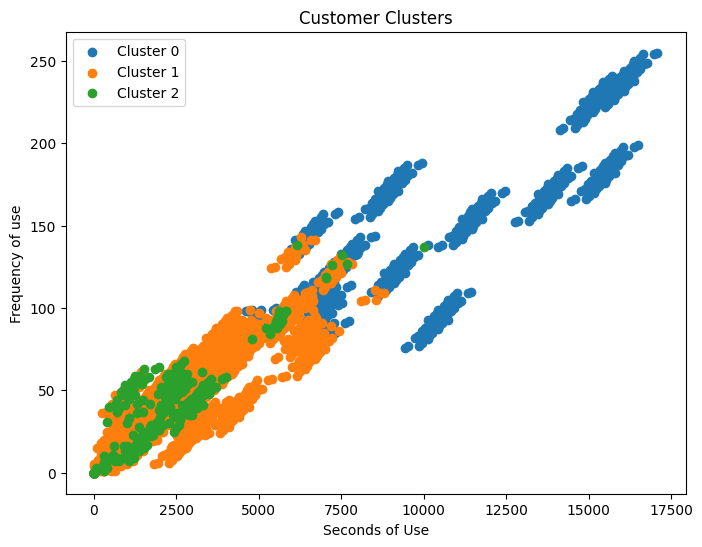

In [22]:
plt.figure(figsize=(8, 6))

for cluster in range(3):
    cluster_data = ul_data[ul_data["Cluster"] == cluster]
    plt.scatter(
        cluster_data["Seconds of Use"],
        cluster_data["Frequency of use"],
        label=f"Cluster {cluster}"
    )

plt.title("Customer Clusters")
plt.xlabel("Seconds of Use")
plt.ylabel("Frequency of use")
plt.legend()
plt.show()

In [23]:
ul_data.groupby("Cluster").mean().round(2)

,Complains,Charge Amount,Seconds of Use,Frequency of use,Age
Cluster,,,,,
0,0.02,2.36,10890.37,153.88,34.41
1,0.00,0.54,2661.66,45.36,29.95
2,1.00,0.42,2156.45,41.76,30.64


Supervised Learning-ში მოდელი სწავლობს წინასწარ ცნობილი პასუხების (Target) საფუძველზე და აკეთებს პროგნოზებს. Unsupervised Learning-ში წინასწარ ცნობილი პასუხები არ გამოიყენება და ალგორითმი მონაცემებში მსგავს ჯგუფებს პოულობს. მოცემულ დავალებაში Decision Tree გამოყენებულია მომხმარებლის წასვლის პროგნოზირებისთვის, ხოლო K-Means — მომხმარებლების დაჯგუფებისთვის.

## ნაწილი 4. Reinforcement Learning - გადაწყვეტილების მიღება



- **Agent:** გადაწყვეტილების მიმღები სისტემა; თითოეული მომხმარებლისთვის ირჩევს შენარჩუნების მოქმედებას.
- **Environment:** სიმულაციური მომხმარებელი; აგენტის მოქმედებაზე აბრუნებს ჯილდოს და ახალ state-ს.
- **State:** მომხმარებლის ტიპი: `0` — მაღალი აქტივობა, `1` — დაბალი აქტივობა საჩივრის გარეშე, `2` — საჩივარი და დაბალი აქტივობა.
- **Action:**
  - `A` — ფასდაკლება (ღირებულება: 4)
  - `B` — პერსონალიზებული SMS (ღირებულება: 1)
  - `C` — გამოტოვება (ღირებულება: 0)
- **Reward:**
 `+10` თუ მომხმარებელი დარჩა
 `-10` თუ წავიდა, მინუს action-ის ღირებულება

###  სიმულაციური გარემოს შექმნა (Environment)

RetentionEnv კლასის საშუალებით შეიქმნა მომხმარებელთა შენარჩუნების გამარტივებული სიმულაციური გარემო.

- **States:** განისაზღვრა მომხმარებლის სამი მდგომარეობა: 0 — მაღალი აქტივობა, 1 — დაბალი აქტივობა საჩივრის გარეშე, 2 — საჩივარი და დაბალი აქტივობა.
- **Actions:** განისაზღვრა სამი შესაძლო მოქმედება: ფასდაკლების შეთავაზება (A), პერსონალიზებული SMS-ის გაგზავნა (B) და მოქმედების გამოტოვება (C).
- **Retention Probability:** თითოეული მდგომარეობისა და მოქმედებისთვის განისაზღვრა მომხმარებლის შენარჩუნების ალბათობა. აღნიშნული მნიშვნელობები სიმულაციის დაშვებებს წარმოადგენს.
- **Action Cost:** თითოეულ მოქმედებას მიენიჭა შესაბამისი ღირებულება: ფასდაკლება — 4, შეტყობინება — 1, მოქმედების გამოტოვება — 0.
- **Reward:** მომხმარებლის შენარჩუნებისთვის განისაზღვრა +10 ჯილდო, ხოლო დაკარგვისთვის -10 ჯარიმა. საბოლოო ჯილდოდან გამოიქვითება არჩეული მოქმედების ღირებულება.

reset() მეთოდი იწყებს ახალ ეპიზოდს და საწყის მდგომარეობას ალბათური განაწილებით ირჩევს (30% / 40% / 30%). step() მეთოდი ასრულებს აგენტის მიერ არჩეულ მოქმედებას, სიმულაციის ალბათობების საფუძველზე განსაზღვრავს მომხმარებლის შენარჩუნებას ან დაკარგვას და აბრუნებს შემდეგ მდგომარეობას, ჯილდოს და ორ ფლაგს: terminated (მომხმარებელი წავიდა) და truncated (ნაბიჯების ლიმიტი ამოიწურა, მომხმარებელი კვლავ აქტიურია).

სიმულაცია შეზღუდულია მაქსიმუმ 5 ნაბიჯით (MAX_STEPS = 5). მომხმარებლის დაკარგვის შემთხვევაში ეპიზოდი სრულდება, ხოლო შენარჩუნების შემთხვევაში გარემო შემდეგ მდგომარეობას ალბათური განაწილებით ირჩევს.

In [24]:
STATE_NAMES = {
    0: "მაღალი აქტივობა",
    1: "დაბალი აქტივობა, საჩივრის გარეშე",
    2: "საჩივარი + დაბალი აქტივობა",
}
ACTION_NAMES = {0: "A - ფასდაკლება",
                1: "B - SMS შეტყობინება",
                2: "C - გამოტოვება"}


class RetentionEnv:
    """Simplified customer retention environment (3 states, 3 actions)."""

    RETENTION_PROB = np.array([
        [0.80, 0.85, 0.90],
        [0.75, 0.80, 0.60],
        [0.70, 0.40, 0.15],])
    ACTION_COST = np.array([4.0, 1.0, 0.0])
    RETAIN_REWARD = 10.0
    CHURN_PENALTY = -10.0
    START_PROBS = np.array([0.3, 0.4, 0.3])
    MAX_STEPS = 5

    def __init__(self, seed=42):
        self.rng = np.random.default_rng(seed)
        self.state = None
        self.steps = 0

    def reset(self):
        """Start a new episode and return the initial state."""
        self.steps = 0
        self.state = int(self.rng.choice(3, p=self.START_PROBS))
        return self.state

    def step(self, action):
        """Apply an action.

        Returns (next_state, reward, terminated, truncated).
        """
        self.steps += 1
        prob = self.RETENTION_PROB[self.state, action]
        retained = self.rng.random() < prob
        outcome = self.RETAIN_REWARD if retained else self.CHURN_PENALTY
        reward = outcome - self.ACTION_COST[action]

        terminated = not retained
        truncated = self.steps >= self.MAX_STEPS
        if retained:
            self.state = int(self.rng.choice(3, p=self.START_PROBS))
        return self.state, reward, terminated, truncated

In [25]:
GAMMA = 0.9
ALPHA_DEMO = 0.1
ALPHA_TRAIN = 0.01


def choose_action(q_table, state, epsilon, rng):
    """Epsilon-greedy action selection."""
    if rng.random() < epsilon:
        return int(rng.integers(q_table.shape[1]))
    return int(np.argmax(q_table[state]))

In [26]:
def update_q(q_table, state, action, reward, next_state, terminated, alpha):
    """One Q-learning update; returns (old_q, td_target, new_q)."""
    old_q = q_table[state, action]
    future = 0.0 if terminated else np.max(q_table[next_state])
    td_target = reward + GAMMA * future
    q_table[state, action] = old_q + alpha * (td_target - old_q)
    return old_q, td_target, q_table[state, action]

In [27]:
demo_env = RetentionEnv(seed=7)
demo_rng = np.random.default_rng(7)
demo_q = np.zeros((3, 3))

state = demo_env.reset()
print(f"{'step':<5}{'state':<7}{'action':<8}{'reward':<9}"
      f"{'next':<6}{'old_q':<8}{'target':<8}{'new_q':<8}")

for step in range(1, 9):
    action = choose_action(demo_q, state, epsilon=1.0, rng=demo_rng)
    next_state, reward, terminated, truncated = demo_env.step(action)
    old_q, target, new_q = update_q(
        demo_q, state, action, reward, next_state, terminated, ALPHA_DEMO
    )
    print(f"{step:<5}{state:<7}{'ABC'[action]:<8}{reward:<9.1f}"
          f"{next_state:<6}{old_q:<8.2f}{target:<8.2f}{new_q:<8.2f}")
    if terminated or truncated:
        state = demo_env.reset()
        print("--- new episode ---")
    else:
        state = next_state

print("\nQ-table after 8 steps:")
print(demo_q.round(2))

step state  action  reward   next  old_q   target  new_q   
1    1      C       -10.0    1     0.00    -10.00  -1.00   
--- new episode ---
2    2      C       -10.0    2     0.00    -10.00  -1.00   
--- new episode ---
3    1      A       -14.0    1     0.00    -14.00  -1.40   
--- new episode ---
4    0      A       -14.0    0     0.00    -14.00  -1.40   
--- new episode ---
5    2      B       -11.0    2     0.00    -11.00  -1.10   
--- new episode ---
6    1      C       10.0     0     -1.00   10.00   0.10    
7    0      C       10.0     1     0.00    10.09   1.01    
8    1      A       6.0      2     -1.40   6.00    -0.66   

Q-table after 8 steps:
[[-1.4   0.    1.01]
 [-0.66  0.    0.1 ]
 [ 0.   -1.1  -1.  ]]


### Q-Learning

Q-Learning იყენებს Q-table-ს, სადაც ინახება თითოეული მდგომარეობისა და მოქმედების შეფასება. თავდაპირველად ყველა მნიშვნელობა 0-ია და სწავლის პროცესში მიღებული ჯილდოს მიხედვით ახლდება.

განახლების ფორმულა:

`Q(s, a) ← Q(s, a) + α · [ r + γ · max Q(s', a') − Q(s, a) ]`

- α (Alpha): განსაზღვრავს ძველი ქულის ცვლილების სიჩქარეს.
- γ (Gamma): განსაზღვრავს მომავალი ჯილდოს მნიშვნელობას.
- r: მიღებული ჯილდო.

მოქმედების არჩევა (Epsilon-greedy): აგენტი ზოგჯერ შემთხვევით ირჩევს მოქმედებას ახალი შესაძლებლობების გამოსაცდელად, დანარჩენ შემთხვევაში კი ყველაზე მაღალი Q-ქულის მქონეს. დემოში ε = 1.0, ამიტომ არჩევანი ყოველთვის შემთხვევითია.

შედეგები: მომხმარებლის წასვლისას ჯილდო უარყოფითია და Q-ქულა მცირდება, დარჩენისას კი დადებითი ჯილდო ქულას ზრდის. თუ მომხმარებელი წავიდა, მომავალი ჯილდო აღარ გაითვალისწინება.

In [28]:
EPSILON = 0.3
EPISODES = 30000
SEED = 42

env = RetentionEnv(seed=SEED)
rng = np.random.default_rng(SEED)
q_table = np.zeros((3, 3))

for _ in range(EPISODES):
    state = env.reset()
    terminated = truncated = False
    while not (terminated or truncated):
        action = choose_action(q_table, state, EPSILON, rng)
        next_state, reward, terminated, truncated = env.step(action)
        update_q(q_table, state, action, reward, next_state,
                 terminated, ALPHA_TRAIN)
        state = next_state

print("Learned Q-table:")
print(pd.DataFrame(q_table.round(2), index=list(STATE_NAMES.values()),
                   columns=["A", "B", "C"]))

Learned Q-table:
                                      A      B      C
მაღალი აქტივობა                   15.06  18.92  22.38
დაბალი აქტივობა, საჩივრის გარეშე  12.22  18.52  12.03
საჩივარი + დაბალი აქტივობა         9.94   4.99  -5.69


In [29]:
for state in range(3):
    best_action = np.argmax(q_table[state])
    print(
        STATE_NAMES[state],
        "->",
        ACTION_NAMES[best_action]
    )

მაღალი აქტივობა -> C - გამოტოვება
დაბალი აქტივობა, საჩივრის გარეშე -> B - SMS შეტყობინება
საჩივარი + დაბალი აქტივობა -> A - ფასდაკლება


**Q-table და პარამეტრები**
- შეიქმნა Q-table: თითოეული მდგომარეობისა და მოქმედების წყვილისთვის ინახავს Q-მნიშვნელობას. თავდაპირველად ყველა მნიშვნელობა ნულია.
- `GAMMA = 0.9` — მომავალი ჯილდოს მნიშვნელობა.
- `ALPHA_TRAIN = 0.01` — სწავლის სიჩქარე (დემოში გამოყენებულია `ALPHA_DEMO = 0.1`, რომ ცალკეული განახლებები ჩანდეს).
- `EPSILON = 0.3` — შემთხვევითი მოქმედების არჩევის ალბათობა.

**ფუნქციები**
- `choose_action()` — Epsilon-Greedy სტრატეგიით არჩევს მოქმედებას.
- `update_q()` — ჯილდოსა და შემდეგი მდგომარეობის საფუძველზე აახლებს Q-მნიშვნელობას.

**სწავლება და შედეგი**
- აგენტი 30000 ეპიზოდზე ისწავლა (`SEED = 42`).
- საუკეთესო მოქმედება თითოეული მდგომარეობისთვის:
  - მაღალი აქტივობა → `C` (გამოტოვება)
  - დაბალი აქტივობა, საჩივრის გარეშე → `B` (პერსონალიზებული SMS)
  - საჩივარი და დაბალი აქტივობა → `A` (ფასდაკლება)

**რატომ არის ეს ლოგიკური**
- ისედაც აქტიურ მომხმარებელზე ფასდაკლება ზედმეტი ხარჯია.
- საჩივრის გარეშე დაბალაქტიურ მომხმარებელს იაფი SMS საკმარისია.
- საჩივრის მქონე მომხმარებლის შესანარჩუნებლად საჭიროა უფრო ძლიერი სტიმული.

**რატომ აღემატება Q ერთი ნაბიჯის ჯილდოს**
- Q-ში ჩართულია მომავალი ჯილდოც (`GAMMA = 0.9`).
- მომხმარებლის შენარჩუნება მომავალ თვეებშიც ახალ ჯილდოს იძლევა.

**შეზღუდვა**
- ალბათობები და ჯილდოები ჩვენ განვსაზღვრეთ (სიმულაციის დაშვებებია).
- შედეგი აჩვენებს სწავლის მექანიზმს და არა რეალურ ბიზნეს-ეფექტს.

Reinforcement Learning-ში აგენტი სწავლობს ცდისა და შეცდომის პრინციპით: ირჩევს მოქმედებას, იღებს ჯილდოს და მიღებული გამოცდილების საფუძველზე აახლებს Q-Table-ს. სწავლის პროცესის გამეორებით ის პოულობს საუკეთესო მოქმედებას თითოეული მდგომარეობისთვის.

**Supervised Learning-ისგან განსხვავება:**
- **Supervised Learning:** მოდელი სწავლობს წინასწარ მონიშნული მონაცემებით და პროგნოზირებს პასუხს.
- **Reinforcement Learning:** აგენტი სწავლობს გარემოსთან ურთიერთქმედებით და ჯილდოს მაქსიმიზაციას ცდილობს.

## ნაწილი 5. ნეირონული ქსელები


**შემავალი ფენა:**
- 11 ნეირონი: თითო ნეირონი თითო მახასიათებელს ემთხვევა

**დამალული ფენა:**
- 16 ნეირონი; ისინი ამუშავებენ შემავალ მონაცემებს და სწავლობენ მათ შორის კავშირებს

**გამომავალი ფენა:**
- 1 ნეირონი: აბრუნებს წასვლის ალბათობას (ორობითი კლასიფიკაცია)

**აქტივაციის ფუნქცია:**
- დამალულ ფენაში გამოყენებულია ReLU: f(x) = max(0, x)
- უარყოფით მნიშვნელობებს ნულად გარდაქმნის, დადებითებს უცვლელად ტოვებს.
- ქსელს არაწრფივი კავშირების შესწავლის საშუალებას აძლევს.

**Backpropagation:**
- ქსელი ჯერ პროგნოზს აკეთებს (forward pass) და ითვლის შეცდომას (loss)
- Backpropagation ამ შეცდომას უკუმიმართულებით ავრცელებს ქსელში და ითვლის, თითოეულმა წონამ შეცდომაში რამდენი შეიტანა
- optimizer (ამ შემთხვევაში Adam) ამის მიხედვით ანახლებს წონებს, რომ შეცდომა შემცირდეს
- პროცესი მეორდება იტერაციების განმავლობაში

- მახასიათებლები nn_x და სამიზნე ცვლადი nn_y გამოიყო. მონაცემები დაიყო სასწავლო (80%) და სატესტო (20%) ნაკრებებად, კლასების პროპორციის შენარჩუნებით.




In [30]:
nn_x = data.drop(columns=["Age Group", "Customer Value", "Churn"])
nn_y = data["Churn"]

In [31]:
nn_x_train, nn_x_test, nn_y_train, nn_y_test = train_test_split(nn_x, nn_y, test_size=0.2, random_state=42, stratify=nn_y)

- მონაცემები სტანდარტიზდა StandardScaler-ის გამოყენებით, რათა მახასიათებლები ერთსა და იმავე მასშტაბზე გადასულიყო. სატესტო მონაცემებზე გამოყენებულ იქნა სასწავლო ნაკრებიდან მიღებული პარამეტრები.

In [32]:
nn_scaler = StandardScaler()

nn_x_train_scaled = nn_scaler.fit_transform(nn_x_train)
nn_x_test_scaled = nn_scaler.transform(nn_x_test)

- შეიქმნა Feedforward Neural Network MLPClassifier-ის გამოყენებით. მოდელს აქვს ერთი დამალული ფენა 16 ნეირონით, ReLU აქტივაციის ფუნქციით და მაქსიმუმ 2000 სასწავლო იტერაციით.

In [33]:
nn_model = MLPClassifier(hidden_layer_sizes=(16,), activation="relu", max_iter=2000, random_state=42)

- მოდელი გაიწვრთნა სასწავლო მონაცემებზე. სწავლების პროცესში Backpropagation-ის გამოყენებით განახლდა ნეირონების წონები, რათა შემცირებულიყო პროგნოზირების შეცდომა.

In [34]:
nn_model.fit(nn_x_train_scaled, nn_y_train)

MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=42)

- გაწვრთნილმა მოდელმა სატესტო მონაცემებზე პროგნოზები გააკეთა და შეფასდა მისი სიზუსტე Accuracy, რომელმაც **94.76%** შეადგინა.

In [35]:
nn_y_pred = nn_model.predict(nn_x_test_scaled)

In [36]:
nn_accuracy = accuracy_score(nn_y_test, nn_y_pred)

print("Neural Network Accuracy:", nn_accuracy)

Neural Network Accuracy: 0.9476190476190476


**შედეგების შედარება:**
- ნეირონული ქსელის სიზუსტემ შეადგინა **94.76%**, ხოლო მეორე ნაწილში შექმნილი Decision Tree კლასიფიკატორის — **93.02%**.
- ნეირონულმა ქსელმა დაახლოებით 1.7 პროცენტული პუნქტით უკეთესი შედეგი აჩვენა (630 ტესტური ჩანაწერიდან დაახლოებით 11-ით მეტი სწორი პროგნოზი).
- ორივე მოდელი ერთსა და იმავე სასწავლო/სატესტო დაყოფაზეა შეფასებული (random_state=42, stratify), ამიტომ შედარება სამართლიანია.


## ნაწილი 6. შედარება და დასკვნა


### მეთოდების შედარება, უპირატესობები და ეთიკური რისკები

#### Supervised, Unsupervised და Reinforcement Learning-ის შედარება
- Supervised Learning: მიზანია მონაცემებზე დაყრდნობით პროგნოზირება. იყენებს მონიშნულ მონაცემებს (Features და Labels), ხოლო შედეგია გაწვრთნილი მოდელი, რომელიც ახალ მონაცემებს კლასიფიცირებს ან პროგნოზირებს. მაგალითები: Decision Tree და Neural Network.
- Unsupervised Learning: მიზანია მონაცემებში არსებული ფარული სტრუქტურებისა და ჯგუფების აღმოჩენა. იყენებს არამონიშნულ მონაცემებს და შედეგად იღებს მონაცემთა ჯგუფებს. მაგალითი: K-Means.
- Reinforcement Learning: მიზანია ჯილდოს საფუძველზე ოპტიმალური გადაწყვეტილებების სწავლა. იყენებს აგენტს, გარემოს, მდგომარეობებსა და მოქმედებებს. შედეგად მიიღება სტრატეგია (Policy), რომელიც განსაზღვრავს საუკეთესო მოქმედებას თითოეულ მდგომარეობაში.
#### მეთოდების გამოყენება
- Decision Tree: კლასიფიკაციისა და გადაწყვეტილებების მიღებისთვის.
- K-Means: მომხმარებლების ქცევის მიხედვით ჯგუფებად დასაყოფად.
- Reinforcement Learning: მომხმარებლების შესანარჩუნებლად ოპტიმალური მოქმედებების შესარჩევად.
- Neural Network: რთული და არაწრფივი კავშირების აღმოსაჩენად და პროგნოზირებისთვის.
#### ნეირონული ქსელის უპირატესობები და შეზღუდვები
ნეირონული ქსელის უპირატესობაა რთული კავშირების შესწავლისა და მაღალი სიზუსტის მიღების შესაძლებლობა. თუმცა, მას სჭირდება მეტი გამოთვლითი რესურსი, მონაცემები და სწავლების დრო. ასევე, მისი გადაწყვეტილებების ინტერპრეტაცია შედარებით რთულია.


#### დაკვირვებები და ეთიკური რისკები

**დაკვირვებები:**
1. მომხმარებლების დაახლოებით 15.7% ტოვებს მომსახურებას (მონაცემები დაუბალანსებელია).
2. საჩივრის მქონე მომხმარებლების დაახლოებით 83% ტოვებს მომსახურებას (საჩივრის გარეშე — 10.1%), ამიტომ საჩივარი წასვლის მნიშვნელოვანი ინდიკატორია.
3. ნეირონულმა ქსელმა სატესტო მონაცემებზე 94.76% სიზუსტე აჩვენა, Decision Tree-მ — 93.02%; ორივე აღემატება 84.29%-იან baseline-ს. განსხვავება მცირეა და ერთ ტესტურ ნაკრებზეა დაფუძნებული.

**ეთიკური რისკები:**
- **მიკერძოება:** `Age` მოდელის feature-ია; თუ მოდელი ასაკობრივ ჯგუფებს განსხვავებულად აფასებს, შეიძლება ფასდაკლება ან ყურადღება უსამართლოდ გადანაწილდეს.
- **კონფიდენციალურობა:** ზარების, SMS-ებისა და საჩივრების მონაცემები პერსონალურია; საჭიროა ანონიმიზაცია, მინიმალური მონაცემების გამოყენება და მომხმარებლის თანხმობა.
- **RL სიმულაცია:** ჯილდოები და ალბათობები ჩვენ განვსაზღვრეთ; რეალურ გარემოში ფასდაკლების პოლიტიკა შეიძლება საჩივრის დაფიქსირების სტიმულად იქცეს.

#### დასკვნა

- გამოკვლევამ აჩვენა, რომ მანქანური სწავლების სხვადასხვა მეთოდი განსხვავებული ამოცანებისთვის გამოიყენება.
- მომხმარებელთა გადინების პროგნოზირებისთვის ეფექტური აღმოჩნდა ნეირონული ქსელი და Decision Tree.
- K-Means-მა მომხმარებელთა დაჯგუფების საშუალება მოგვცა (აქტიურობისა და საჩივრის მიხედვით).
- Reinforcement Learning-ით სიმულაციაში აგენტმა ისწავლა მდგომარეობის მიხედვით შენარჩუნების მოქმედების შერჩევა.
